# Analisis Performa Pemrosesan Gambar — Multithreading

Setelah memperoleh baseline sequential, saya melanjutkan eksperimen dengan 2 dan 4 thread. Saya ingin melihat apakah pembagian pekerjaan mempercepat pemrosesan LIGHT dan HEAVY, serta bagaimana CPU dan RAM berubah.

Saya menggunakan transformasi dan batch CIFAR-10 yang sama seperti tahap sebelumnya. Sequential diukur ulang bersama threading agar baseline berasal dari rangkaian pengujian yang sama. Seluruh hasil di notebook ini berasal dari eksekusi lokal; analisis mengikuti CSV yang dihasilkan saat cell eksperimen dijalankan.

## 1. Environment dan input

Notebook memakai `.venv` project. Saya mengambil 10.000 gambar dari `data_batch_1.bin`, masing-masing RGB 32 × 32 piksel. Semua kondisi mendapat input, jumlah gambar, dan parameter transformasi yang sama. Dataset akan dibaca ulang di proses pengukuran, sebelum timer dimulai.

In [1]:
from pathlib import Path
import sys
import subprocess
import json
import inspect
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image as NotebookImage

PROJECT = Path.cwd().resolve()
PYTHON = PROJECT / ".venv" / "Scripts" / "python.exe"
assert Path(sys.prefix).resolve() == (PROJECT / ".venv").resolve(), "Pilih kernel .venv project."
assert (PROJECT / "src" / "threading_processing.py").is_file()
sys.path.insert(0, str(PROJECT / "src"))
from dataset import load_batch
from image_processing import TRANSFORM_CONFIG
from threading_processing import process_chunk, run_threading
images, labels = load_batch()
assert images.shape == (10000, 32, 32, 3)
print("Python:", sys.executable)
print("Dataset:", images.shape, images.dtype)
print("Parameter transformasi:", TRANSFORM_CONFIG)

Python: C:\Lucky\Binus University\S9\Operating System\Operating-System-Assignment\.venv\Scripts\python.exe
Dataset: (10000, 32, 32, 3) uint8
Parameter transformasi: {'resize': [64, 64], 'resampling': 'BILINEAR', 'light': ['resize', 'grayscale'], 'heavy': ['resize', 'rotate', 'gaussian_blur', 'sharpen', 'color', 'find_edges'], 'rotation_degrees': 15, 'rotation_expand': False, 'blur_radius': 2, 'color_factor': 1.2}


## 2. Cara kerja thread

Thread adalah unit eksekusi di dalam satu proses. Pada eksperimen ini thread pengolah membaca array input yang sama, tetapi setiap gambar diubah menjadi objek gambar lokal di fungsi pengolahan. Input tidak dimodifikasi.

Saya memakai `ThreadPoolExecutor(max_workers=2)` dan `max_workers=4`. Angka worker adalah batas thread pengolah, bukan jumlah total thread yang mungkin dimiliki interpreter dan library.

Pada CPython 3.11 biasa, GIL membatasi eksekusi kode Python secara bersamaan. Namun operasi library native dapat melepas GIL. Karena itu, saya mengukur hasilnya terlebih dahulu; saya tidak menganggap threading pasti lebih cepat atau pasti gagal memanfaatkan lebih dari satu logical CPU.

Workload yang digunakan tetap:

| LIGHT | HEAVY |
|---|---|
| Resize 64 × 64 → grayscale | Resize 64 × 64 → rotate 15° → blur radius 2 → sharpen → color 1,2 → edge detection |

## 3. Pembagian pekerjaan dan kesamaan output

Satu task memproses 100 gambar. Program menjaga paling banyak `2 × worker` task yang belum dikonsumsi. Pembatasan ini mencegah antrean 10.000 future sekaligus, tetapi sejumlah output per-chunk masih disimpan sementara di RAM.

Future diambil sesuai urutan task dikirim, walaupun task lain bisa selesai lebih dulu. Ini menjaga urutan byte output tetap sama dengan sequential. Hash SHA-256 diperbarui hanya di thread utama, sehingga worker tidak berebut memperbarui hash yang sama. Konsekuensinya, menunggu task yang lebih awal dan hashing serial dapat membatasi kecepatan.

Di bawah ini saya menampilkan kode yang benar-benar digunakan dalam pengukuran.

In [2]:
print(inspect.getsource(process_chunk))
print(inspect.getsource(run_threading))

def process_chunk(images: np.ndarray, workload: str) -> list[bytes]:
    """Worker hanya membaca input dan mengembalikan byte output sesuai urutan."""
    return [process_image(pixels, workload).tobytes() for pixels in images]

def run_threading(images: np.ndarray, workload: str, workers: int,
                  chunk_size: int = 100, sample_every: int = 100) -> dict:
    if workers not in (2, 4) or len(images) < 1 or min(chunk_size, sample_every) < 1:
        raise ValueError("Worker harus 2/4; jumlah gambar dan interval harus positif")
    gc.collect()
    process = psutil.Process()
    rss_before = process.memory_info().rss / 1024**2
    samples = [{"processed_images": 0, "elapsed_s": 0.0, "rss_mib": rss_before}]
    digest = hashlib.sha256()
    cpu_before = process.cpu_times()
    start = perf_counter()
    # Timer juga mencakup startup dan shutdown pool, serta penjadwalan task.
    with ThreadPoolExecutor(max_workers=workers, thread_name_prefix="image-worker") as pool:
        pen

## 4. Rancangan pengukuran

Saya menguji enam kondisi: sequential, 2 thread, dan 4 thread pada LIGHT serta HEAVY. Masing-masing diulang tiga kali, sehingga ada 18 pengukuran. Urutan keenam kondisi diputar dua posisi pada setiap pengulangan.

Setiap pengukuran dijalankan dalam proses Python baru agar alokasi RAM run sebelumnya tidak terbawa. Pemisahan proses ini hanya cara menjalankan pengukuran; worker pengolah pada konfigurasi threading tetap berupa thread dalam satu proses.

| Bagian | Kebijakan |
|---|---|
| Input | Batch pertama, 10.000 gambar, read-only |
| Warm-up | 50 gambar untuk transformasi workload terkait; di luar timer |
| Timer | Konversi gambar, transformasi, byte output, hash, sampling RSS |
| Timer threading | Juga mencakup pembuatan/penutupan pool, submit, dan menunggu task |
| Di luar timer | Startup interpreter, load dataset, warm-up, CSV, dan grafik |
| CPU | CPU time proses / wall time × 100%; 100% setara satu logical CPU |
| RAM | RSS di awal, setiap 100 output dikonsumsi, dan setelah shutdown pool |
| Speedup ringkasan | Rata-rata waktu sequential / rata-rata waktu metode, untuk workload sama |

Warm-up tidak membuat pool persistent: setiap run threading mempunyai pool baru. Maksimum RSS hanya maksimum yang tertangkap sampel. Error bar waktu menggunakan sample SD, bukan confidence interval.

In [3]:
NUMBER_OF_IMAGES = 10000
REPETITIONS = 3
WARMUP_IMAGES = 50
completed = subprocess.run(
    [str(PYTHON), str(PROJECT / "main.py"), "--experiment", "threading",
     "--images", str(NUMBER_OF_IMAGES), "--repetitions", str(REPETITIONS),
     "--warmup", str(WARMUP_IMAGES)],
    cwd=PROJECT, capture_output=True, text=True, check=True,
)
print(completed.stdout)
if completed.stderr:
    print(completed.stderr)
result_line = next(line for line in completed.stdout.splitlines() if line.startswith("RESULT_DIR="))
RESULT_DIR = Path(result_line.removeprefix("RESULT_DIR="))
status = json.loads((RESULT_DIR / "status.json").read_text(encoding="utf-8"))
assert status["complete"] and status["measured_runs"] == 6 * REPETITIONS
environment = json.loads((RESULT_DIR / "environment.json").read_text(encoding="utf-8"))
display(pd.DataFrame({"Informasi": ["Waktu", "Python", "CPU", "Logical CPU", "RAM terpasang (GiB)"],
                      "Nilai": [environment["timestamp"], environment["python"], environment["cpu"],
                                environment["logical_cpus"], round(environment["total_ram_gib"], 2)]}))

Run 1/3: LIGHT sequential 1
  0.456 s | 21953.0 gambar/s | CPU proses 99.5%
Run 1/3: LIGHT threading 2
  0.694 s | 14412.0 gambar/s | CPU proses 137.4%
Run 1/3: LIGHT threading 4
  0.735 s | 13613.6 gambar/s | CPU proses 148.9%
Run 1/3: HEAVY sequential 1
  3.606 s | 2773.2 gambar/s | CPU proses 98.8%
Run 1/3: HEAVY threading 2
  2.715 s | 3683.5 gambar/s | CPU proses 173.8%
Run 1/3: HEAVY threading 4
  2.594 s | 3855.3 gambar/s | CPU proses 223.5%
Run 2/3: LIGHT threading 4
  1.331 s | 7512.4 gambar/s | CPU proses 140.9%
Run 2/3: HEAVY sequential 1
  3.493 s | 2862.7 gambar/s | CPU proses 98.0%
Run 2/3: HEAVY threading 2
  2.716 s | 3681.3 gambar/s | CPU proses 172.6%
Run 2/3: HEAVY threading 4
  2.735 s | 3656.9 gambar/s | CPU proses 220.6%
Run 2/3: LIGHT sequential 1
  0.464 s | 21529.7 gambar/s | CPU proses 97.6%
Run 2/3: LIGHT threading 2
  0.722 s | 13853.3 gambar/s | CPU proses 121.2%
Run 3/3: HEAVY threading 2
  2.681 s | 3729.8 gambar/s | CPU proses 174.3%
Run 3/3: HEAVY threa

,Informasi,Nilai
0,Waktu,2026-10-05T13:34:17.038446+07:00
1,Python,3.11.9
2,CPU,Intel(R) Core(TM) Ultra 9 185H
3,Logical CPU,22
4,RAM terpasang (GiB),31.43


## 5. Hasil mentah dan validasi

Saya memeriksa seluruh run sebelum mengambil rata-rata. Hash harus sama antar-metode dan antar-pengulangan untuk workload yang sama. Pemeriksaan ini membantu memastikan bahwa peningkatan performa tidak terjadi karena program melewatkan gambar atau mengubah urutan output.

Kolom speedup per-run memakai rata-rata sequential sebagai pembilang. Nilai per-run sequential bisa berbeda dari 1, sedangkan speedup ringkasan sequential adalah tepat 1.

In [4]:
raw = pd.read_csv(RESULT_DIR / "raw_results.csv")
assert len(raw) == 6 * REPETITIONS
assert raw.groupby(["workload", "method", "workers"]).size().eq(REPETITIONS).all()
assert raw.groupby(["workload", "method", "workers"]).size().size == 6
assert (raw["images"] == NUMBER_OF_IMAGES).all()
assert raw.groupby("workload")["output_sha256"].nunique().eq(1).all()
assert (raw["time_s"] > 0).all()
assert np.allclose(raw.throughput_images_s * raw.time_s, NUMBER_OF_IMAGES)
assert (raw.rss_peak_sampled_mib >= raw.rss_before_mib).all()
display(raw[["sequence_index", "run", "workload", "method", "workers", "time_s",
             "throughput_images_s", "cpu_process_percent", "rss_peak_sampled_mib"]].round(3))
print("Validasi 18 pengukuran, jumlah input, throughput, RSS, dan hash: lolos.")

,sequence_index,run,workload,method,workers,time_s,throughput_images_s,cpu_process_percent,rss_peak_sampled_mib
0,1,1,light,sequential,1,0.456,21953.029,99.475,65.941
1,2,1,light,threading,2,0.694,14411.980,137.364,67.516
2,3,1,light,threading,4,0.735,13613.612,148.899,70.102
3,4,1,heavy,sequential,1,3.606,2773.193,98.795,65.980
4,5,1,heavy,threading,2,2.715,3683.455,173.813,68.656
5,6,1,heavy,threading,4,2.594,3855.315,223.488,71.680
6,7,2,light,threading,4,1.331,7512.392,140.857,70.535
7,8,2,heavy,sequential,1,3.493,2862.670,97.957,65.832
8,9,2,heavy,threading,2,2.716,3681.277,172.560,68.941
9,10,2,heavy,threading,4,2.735,3656.861,220.554,71.418


Validasi 18 pengukuran, jumlah input, throughput, RSS, dan hash: lolos.


## 6. Perbandingan rata-rata dan speedup

Speedup di atas 1 berarti metode tersebut lebih cepat daripada sequential. Nilai di bawah 1 berarti lebih lambat. Misalnya speedup 0,5 berarti waktu metode sekitar dua kali baseline, bukan lebih cepat 50%.

Saya juga menghitung efficiency sebagai `speedup / worker × 100%`. Ini menggambarkan peningkatan kecepatan relatif terhadap jumlah worker, bukan persentase CPU yang digunakan. Rata-rata throughput di tabel adalah rata-rata throughput masing-masing run.

,workload,method,workers,runs,mean_time_s,std_time_s,mean_throughput_images_s,speedup,efficiency_percent
0,heavy,sequential,1,3,3.676,0.225,2727.376,1.000,100.000
1,heavy,threading,2,3,2.704,0.020,3698.175,1.359,67.961
2,heavy,threading,4,3,2.626,0.097,3811.841,1.400,34.995
3,light,sequential,1,3,0.460,0.005,21763.649,1.000,100.000
4,light,threading,2,3,0.709,0.014,14117.913,0.649,32.428
5,light,threading,4,3,0.927,0.350,11699.277,0.496,12.391


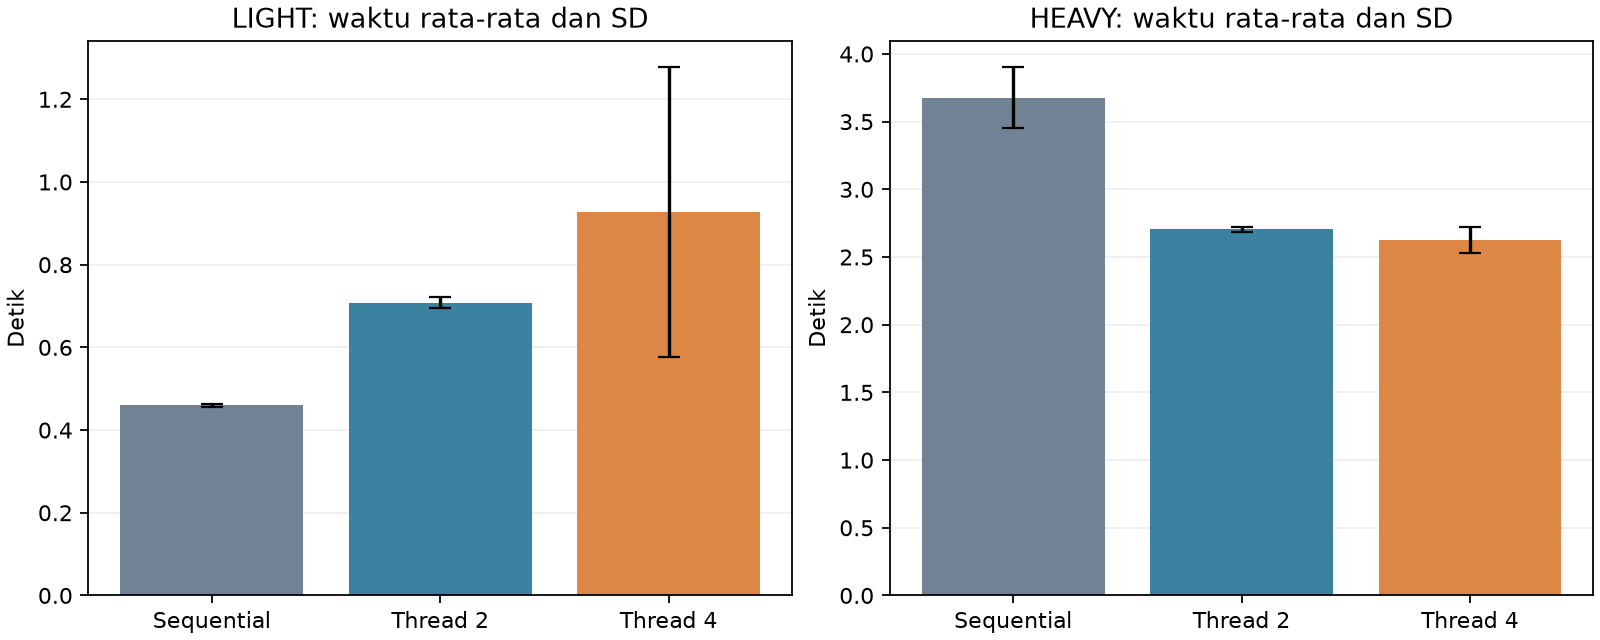

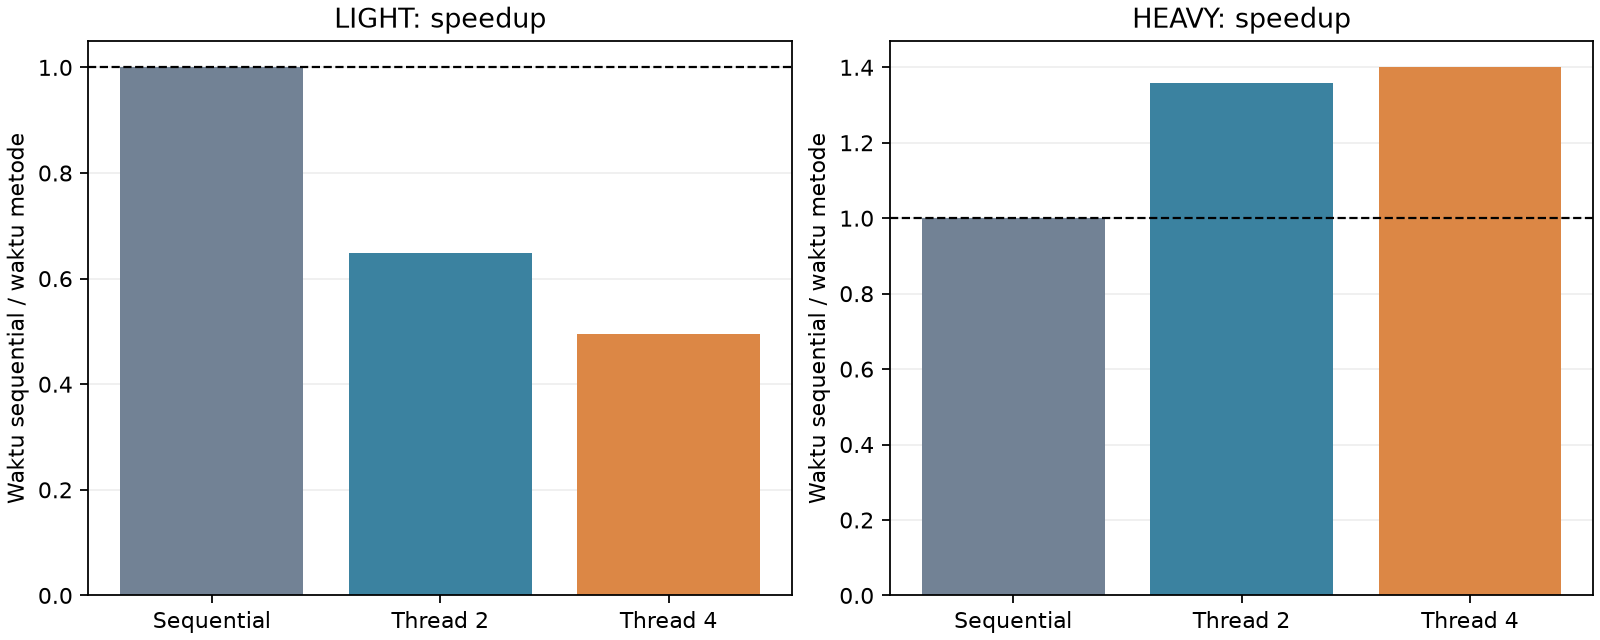

In [5]:
summary = pd.read_csv(RESULT_DIR / "summary.csv")
baseline = summary[summary.method == "sequential"].set_index("workload").mean_time_s
assert np.allclose(summary.speedup, summary.workload.map(baseline) / summary.mean_time_s)
assert np.allclose(summary[summary.method == "sequential"].speedup, 1)
display(summary[["workload", "method", "workers", "runs", "mean_time_s", "std_time_s",
                 "mean_throughput_images_s", "speedup", "efficiency_percent"]].round(3))
display(NotebookImage(filename=str(RESULT_DIR / "figures" / "time_comparison.png")))
display(NotebookImage(filename=str(RESULT_DIR / "figures" / "speedup.png")))

## 7. CPU dan RAM

Saya membaca penggunaan resource bersama waktu eksekusi. CPU yang lebih tinggi belum tentu membuat program selesai lebih cepat. CPU proses juga bisa melebihi 100% karena CPU time seluruh thread di proses dijumlahkan.

RAM mencakup dataset, interpreter, library, thread, dan output sementara. Grafik menggunakan rata-rata maksimum RSS tersampel per-run dengan sumbu dari nol. Angka ini bukan penjumlahan RAM tiap thread dan bukan peak RAM kontinu.

,workload,method,workers,mean_cpu_process_percent,mean_rss_before_mib,mean_rss_peak_sampled_mib,max_rss_peak_sampled_mib
0,heavy,sequential,1,98.208,65.612,65.980,66.129
1,heavy,threading,2,173.541,65.668,68.820,68.941
2,heavy,threading,4,224.846,65.693,71.727,72.082
3,light,sequential,1,98.617,65.691,65.878,65.941
4,light,threading,2,124.350,65.654,67.564,67.668
5,light,threading,4,147.524,65.717,70.125,70.535


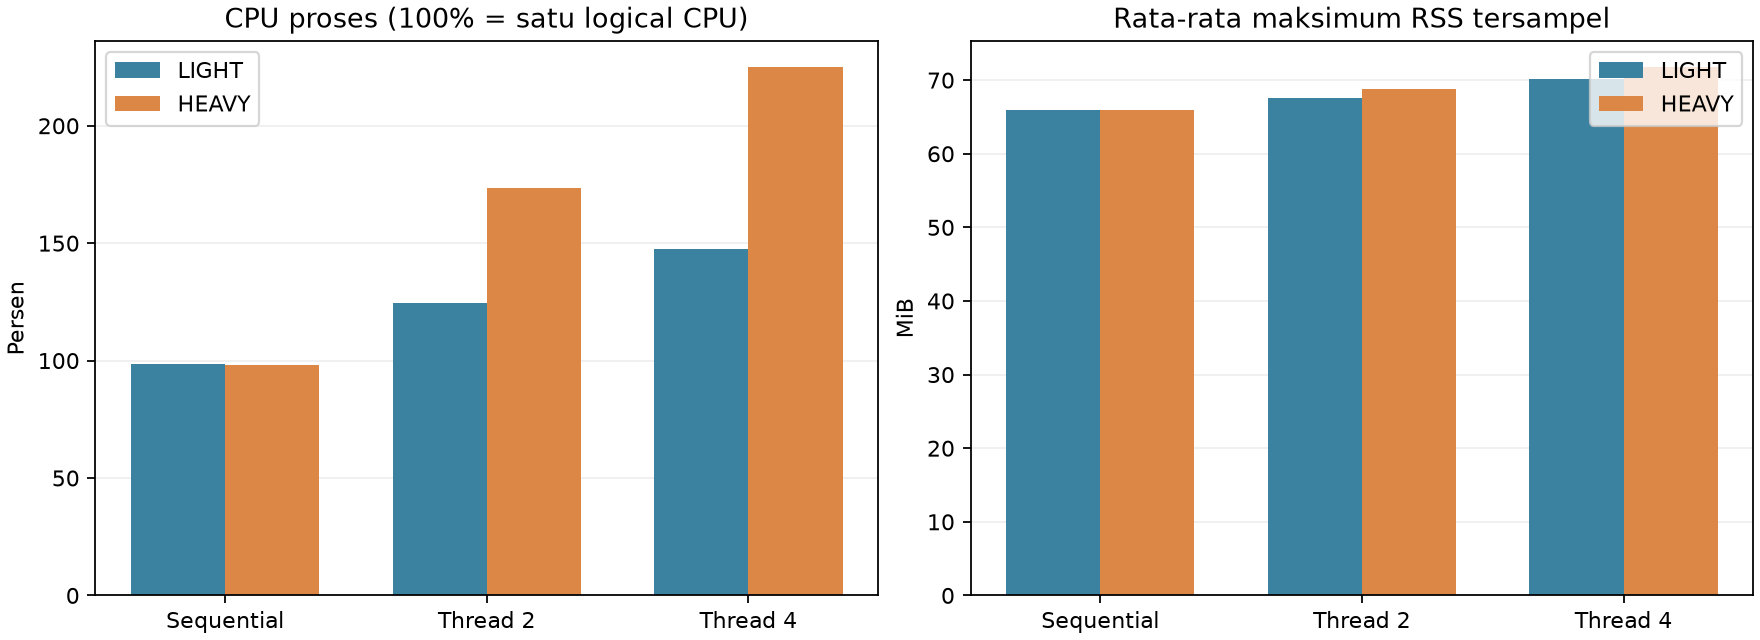

In [6]:
display(summary[["workload", "method", "workers", "mean_cpu_process_percent",
                 "mean_rss_before_mib", "mean_rss_peak_sampled_mib", "max_rss_peak_sampled_mib"]].round(3))
display(NotebookImage(filename=str(RESULT_DIR / "figures" / "resources.png")))

## 8. Analisis hasil aktual

Analisis di bawah dihitung dari hasil run pada notebook ini. Saya membedakan angka yang terukur dari dugaan penyebabnya. Penjelasan tentang GIL, antrean, dan scheduling digunakan sebagai konteks; eksperimen ini belum memisahkan biaya masing-masing komponen.

In [7]:
display(Markdown((RESULT_DIR / "analysis.md").read_text(encoding="utf-8")))

# Analisis Sequential dan Multithreading

Saya membandingkan sequential, 2 thread, dan 4 thread pada batch pertama CIFAR-10. Setiap kondisi dijalankan tiga kali secara default, dengan proses pengukuran baru, warm-up transformasi, serta parameter LIGHT/HEAVY yang sama. Sequential diukur ulang pada rangkaian ini dan menjadi pembagi speedup, sehingga angka notebook sebelumnya tidak dicampur ke perbandingan ini.

## Hasil

| Workload | Metode | Worker | Run | Waktu rata-rata (s) | SD (s) | Gambar/s | Speedup | CPU proses (%) | RSS peak tersampel rata-rata (MiB) |
|---|---|---:|---:|---:|---:|---:|---:|---:|---:|
| HEAVY | sequential | 1 | 3 | 3.676 | 0.225 | 2727.4 | 1.00 | 98.2 | 65.98 |
| HEAVY | threading | 2 | 3 | 2.704 | 0.020 | 3698.2 | 1.36 | 173.5 | 68.82 |
| HEAVY | threading | 4 | 3 | 2.626 | 0.097 | 3811.8 | 1.40 | 224.8 | 71.73 |
| LIGHT | sequential | 1 | 3 | 0.460 | 0.005 | 21763.6 | 1.00 | 98.6 | 65.88 |
| LIGHT | threading | 2 | 3 | 0.709 | 0.014 | 14117.9 | 0.65 | 124.3 | 67.56 |
| LIGHT | threading | 4 | 3 | 0.927 | 0.350 | 11699.3 | 0.50 | 147.5 | 70.12 |

## Pembacaan hasil

Pada LIGHT, rata-rata sequential 0.460 detik, 2 thread 0.709 detik, dan 4 thread 0.927 detik. Speedup 2 thread adalah 0.65 dan 4 thread 0.50. Rata-rata tercepat pada kondisi ini adalah sequential. Speedup di atas 1 berarti lebih cepat, sedangkan di bawah 1 berarti lebih lambat dibanding sequential.

Variasi waktu (SD/rata-rata) untuk sequential, 2 thread, dan 4 thread masing-masing 0.99%, 1.98%, dan 37.75%. Tiga pengulangan merupakan gambaran awal; saya belum melakukan uji signifikansi atau pengukuran terpisah untuk membuktikan penyebab selisih waktu.

Penambahan dari 2 ke 4 thread tidak menurunkan rata-rata waktu pada workload ini. Hasil ini memperlihatkan bahwa menambah worker tidak otomatis mempercepat pipeline.

Pada HEAVY, rata-rata sequential 3.676 detik, 2 thread 2.704 detik, dan 4 thread 2.626 detik. Speedup 2 thread adalah 1.36 dan 4 thread 1.40. Rata-rata tercepat pada kondisi ini adalah threading 4 worker. Speedup di atas 1 berarti lebih cepat, sedangkan di bawah 1 berarti lebih lambat dibanding sequential.

Variasi waktu (SD/rata-rata) untuk sequential, 2 thread, dan 4 thread masing-masing 6.13%, 0.74%, dan 3.69%. Tiga pengulangan merupakan gambaran awal; saya belum melakukan uji signifikansi atau pengukuran terpisah untuk membuktikan penyebab selisih waktu.

Penambahan dari 2 ke 4 thread menurunkan rata-rata waktu pada workload ini, tetapi saya tidak menganggap peningkatannya selalu linear dengan jumlah worker.

## Hubungan dengan Operating System

Thread pengolah berada dalam satu proses dan membaca dataset yang sama. Dengan begitu tidak ada proses pengolah baru atau penyalinan dataset antar-proses. Namun thread tetap membutuhkan stack, penjadwalan, antrean task, dan koordinasi output. Pipeline ini juga menyimpan sejumlah output sementara dalam chunk. Karena itu, perubahan RSS tidak dapat dianggap berasal dari stack thread saja.

CPython 3.11 biasa menggunakan Global Interpreter Lock (GIL) untuk eksekusi kode Python. Operasi library native dapat melepas GIL, sehingga saya tidak menyimpulkan semua pemrosesan gambar pasti serial hanya karena menggunakan Python. Sebaliknya, lebih banyak thread juga tidak menjamin paralelisme efektif. Overhead task, koordinasi hash pada thread utama, penantian hasil sesuai urutan, dan bagian yang memegang GIL merupakan penjelasan yang mungkin; eksperimen ini tidak mengisolasi kontribusi masing-masing.

Komputer pengujian memiliki 22 logical CPU. CPU proses 100% setara satu logical CPU dan bisa melebihi 100% jika CPU time beberapa thread bertambah secara bersamaan. CPU time yang lebih besar tidak selalu berarti pekerjaan selesai lebih cepat: pemakaian CPU harus dibaca bersama wall time. RSS adalah memori proses, bukan seluruh pemakaian RAM komputer.

## Validasi dan batasan

SHA-256 byte output sama antara sequential, 2 thread, dan 4 thread untuk workload yang sama pada seluruh pengulangan. Ini memeriksa kesamaan output, bukan kualitas gambar. Hash hanya diperbarui pada thread utama, dan future dikonsumsi sesuai urutan pengiriman agar urutan gambar tetap sama. Input dibuat read-only.

Satu task berisi 100 gambar; maksimum 2 x worker task belum dikonsumsi pada satu saat. Ini mencegah pembuatan 10.000 future sekaligus, tetapi buffering output dan chunk size tetap memengaruhi hasil. Kesimpulan berlaku untuk implementasi serta chunk size ini. Saya belum membandingkan ukuran chunk lain, pool persistent, atau output yang disimpan ke disk.

Timer threading mencakup startup/shutdown pool, submit/wait task, transformasi, konversi ke byte, hash, dan sampling RSS. Startup interpreter, load dataset, warm-up transformasi, dan penulisan laporan berada di luar timer. Warm-up tidak membuat pool thread yang dipakai pada run berikutnya; setiap run menggunakan pool baru. Sequential menggunakan batas timer yang sama untuk pekerjaan pengolahan dan hash.

RSS diambil setiap 100 output yang dikonsumsi dan setelah shutdown pool, bukan secara kontinu; puncak singkat bisa terlewat. Setiap run memakai proses baru untuk mengurangi carry-over memori. Kondisi tetap diputar urutannya, tetapi background task dan perubahan kondisi CPU masih mungkin memengaruhi waktu. Pengukuran di bawah satu detik terutama sensitif terhadap gangguan kecil dan resolusi CPU time. Sebelum generalisasi, diperlukan lebih banyak pengulangan atau input lebih besar.

## Kesimpulan sementara

Saya sudah memperoleh perbandingan sequential dan threading 2/4 worker pada dua workload. Saya memilih interpretasi berdasarkan waktu, resource, dan kesamaan output secara bersama. Hasil ini belum menjawab performa multiprocessing; langkah berikutnya adalah menguji 2 dan 4 process dengan pekerjaan serta validasi yang setara.

## Referensi

- https://docs.python.org/3.11/library/concurrent.futures.html#concurrent.futures.ThreadPoolExecutor
- https://docs.python.org/3.11/library/threading.html
- https://www.cs.toronto.edu/~kriz/cifar.html


## 9. Catatan sebelum melanjutkan

Saya sudah dapat membandingkan sequential dengan threading pada dua tingkat pekerjaan. Kesimpulan saya berlaku untuk dataset, ukuran kerja 64 × 64, chunk 100 gambar, antrean terbatas, dan pool baru per-run yang digunakan di sini.

Tiga pengulangan memberi gambaran awal. Workload singkat sensitif terhadap gangguan, dan maksimum RSS bisa melewatkan puncak di antara sampel. Saya belum menentukan apakah multiprocessing lebih baik karena konfigurasi tersebut belum diuji.

Langkah berikutnya adalah menguji 2 dan 4 process dengan fungsi transformasi serta validasi output yang sama, lalu menyusun perbandingan ketiga metode.

## Referensi

- [ThreadPoolExecutor — Python 3.11](https://docs.python.org/3.11/library/concurrent.futures.html#concurrent.futures.ThreadPoolExecutor).
- [Threading dan GIL — Python 3.11](https://docs.python.org/3.11/library/threading.html).
- [Dataset CIFAR-10](https://www.cs.toronto.edu/~kriz/cifar.html).